## Setting Up the Libs and Syn2 Configurations

In [1]:
from __future__ import print_function
import time
import torch
import torch.nn as nn
import numpy as np
import scipy.ndimage
import matplotlib
import matplotlib.pyplot as plt
import deepwave
import os
from timeit import default_timer as timer
import scipy.io as spio
import math
import numpy as np
from utils.utils import *
from torch import optim
from IPython.core.debugger import set_trace 
import random
from __future__ import print_function
torch.manual_seed(0)
random.seed(0)

####################################################
####   MAIN PARAMETERS FOR FORWARD MODELING         ####
####################################################

peak_freq = 6                    # central frequency
peak_source_time = 1 / peak_freq  # the time (in secs) of the peak amplitude
dx        = 30.0                  # step interval along x/z direction
dt        = 0.003                 # time interval (e.g., 3ms)
num_dims  = 2                     # dimension of velocity model
nz        = 256                   # model shape of z dimension (depth) Syn2
ny        = 511                   # model shape of y dimension Syn2
vmodel_dim = np.array([nz, ny])

total_t   = 6.                      # totle sampling time (unit: s)
nt        = int(total_t / dt)       # number of time sampling points
num_shots = 30                      # nunmber of shots
num_sources_per_shot = 1            # number of sources per shot
num_receivers_per_shot = ny        # number of receivers per shot
source_spacing = np.floor(dx * ny / (num_shots+1))                         # space intervel between neigbouring sources
receiver_spacing = np.floor(dx * ny / (num_receivers_per_shot +1))         # space intervel between neigbouring receivers
source_depth = 0                # the index depth of sources, default is 0
receiver_depth = 0              # the index depths of receivers, default is 0
order          = 8              # precision order of finite difference in space domain
pml_width  = [0,10,10,10]   # pml padding width for boundary (0 for free surface and 10 for absorbing boundary)

fwi_lr            = 10        # learning rate for updating the model.
fwi_batch         =   num_shots      # number of batches for FWI.
fwi_num_epochs    = 200       # number of FWI iteration.
sim_lr            = 1e-3   # learning rate for Soamese network.
sim_lr1            = 1e-5   # learning rate for Soamese network.

survey_pad = None
savepoch = 20                 # Saving models each 50 FWI iterations


d_source = np.floor( dx*(ny / (num_shots+1)) )    # 20 * 4m = 80m
first_source = 18*dx  # 10 * 4m = 40m
source_depth = 0  # 2 * 4m = 8m

d_receiver = np.floor( dx*(ny / (num_receivers_per_shot)) )    # 6 * 4m = 24m
first_receiver = 0  # 0 * 4m = 0m
receiver_depth = 0  # 2 * 4m = 8m

##   Check Cuda Device 


In [2]:
torch.backends.cudnn.enabled = True
torch.backends.cudnn.benchmark = True

cuda_available = torch.cuda.is_available()
device = torch.device("cuda" if cuda_available else "cpu")
device 

device(type='cuda')

In [3]:
from deepwave import scalar
from scipy.ndimage import gaussian_filter
import torch
import numpy as np

fwi_result = 'results/DIIP_Syn2/'

if not os.path.exists(fwi_result):
    # Create the directory
    os.makedirs(fwi_result)
    print(f"Directory '{fwi_result}' created.")
else:
    print(f"Directory '{fwi_result}' already exists.")
    
# Loading the true model
model_true = np.load('data/Vel_True_Syn2.npy')

# The model will be updated during FWI
# move to numpy
model_np = model_true

water_top = 0
# true velocity model
model_true = torch.tensor(model_true, dtype=torch.float32, device=device)

# detect water mask
water_mask = model_true <= 1550.0   # tolerance around 1500

# optional: enforce continuous top water layer only
water_bottom = water_mask.float().sum(dim=0).min().long().item()

print("Water depth samples:", water_bottom)



# copy to avoid in-place modification
model_smooth = model_np.copy()

# indices of water layer
#water_top = 0
#water_bottom = 34  # excluded from smoothing

# apply smoothing ONLY below water layer
model_smooth= gaussian_filter(
    model_np,
    sigma=[20, 20]
)

# explicitly enforce water velocity (optional but recommended)
model_smooth[water_top:water_bottom, :] = 1500.0

# back to torch
model = torch.from_numpy(model_smooth).to(device)
model_init = torch.from_numpy(model_smooth).to(device)


model      = interp_depth_to_256(model,      256)
model_init = interp_depth_to_256(model_init, 256)
model = torch.nn.Parameter(model)

# Creating source and reciver locations
# x_s
x_s = torch.zeros(num_shots, num_sources_per_shot, 2,
                               dtype=torch.long, device=device)
x_s[:,0,0] = source_depth
x_s[:,0,1] = (torch.arange(num_shots) * d_source +
                             first_source)

# x_r
x_r = torch.zeros(num_shots, num_receivers_per_shot, 2,
                                 dtype=torch.long, device=device)
x_r[:,:,0] = receiver_depth
x_r[0,:,1] = (
    (torch.arange(num_receivers_per_shot) * d_receiver +
     first_receiver)
)
x_r[:, :, 1] = x_r[0, :, 1].repeat(num_shots, 1)

    
#dx1 = 4*dx
x_s = torch.floor(x_s/dx) 
x_r = torch.floor(x_r/dx) 

# source_amplitudes
source_amplitudes = (
    deepwave.wavelets.ricker(peak_freq, nt, dt, peak_source_time)
)

source = source_amplitudes.repeat(num_shots,num_sources_per_shot,1)
source_amplitudes_init = source
# receiver Amplitude
receiver_amplitudes_true = scalar(model_true.to(device), dx, dt, source_amplitudes=source.to(device),
                 source_locations=x_s.to(device),
                 receiver_locations=x_r.to(device),
                 accuracy=8,
                 pml_width=pml_width,
                 pml_freq = peak_freq)[-1]

# Mute Frequency below 3 Hz
receiver_amplitudes_true = highpass_filter(3, receiver_amplitudes_true.cpu(), dt=dt, pad=[10, 10, 0, 0, 0, 0]).to(device)

rcv_amps_true = receiver_amplitudes_true.clone()
rcv_amps_true.shape

Directory 'results/DIIP_Syn2/' already exists.
Water depth samples: 28


/home/sadalyom/.conda/envs/DAS_Denoising_Torch/lib/python3.8/site-packages/torch/cuda/__init__.py:611: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


torch.Size([30, 511, 2000])

## Plotting the inital and true model


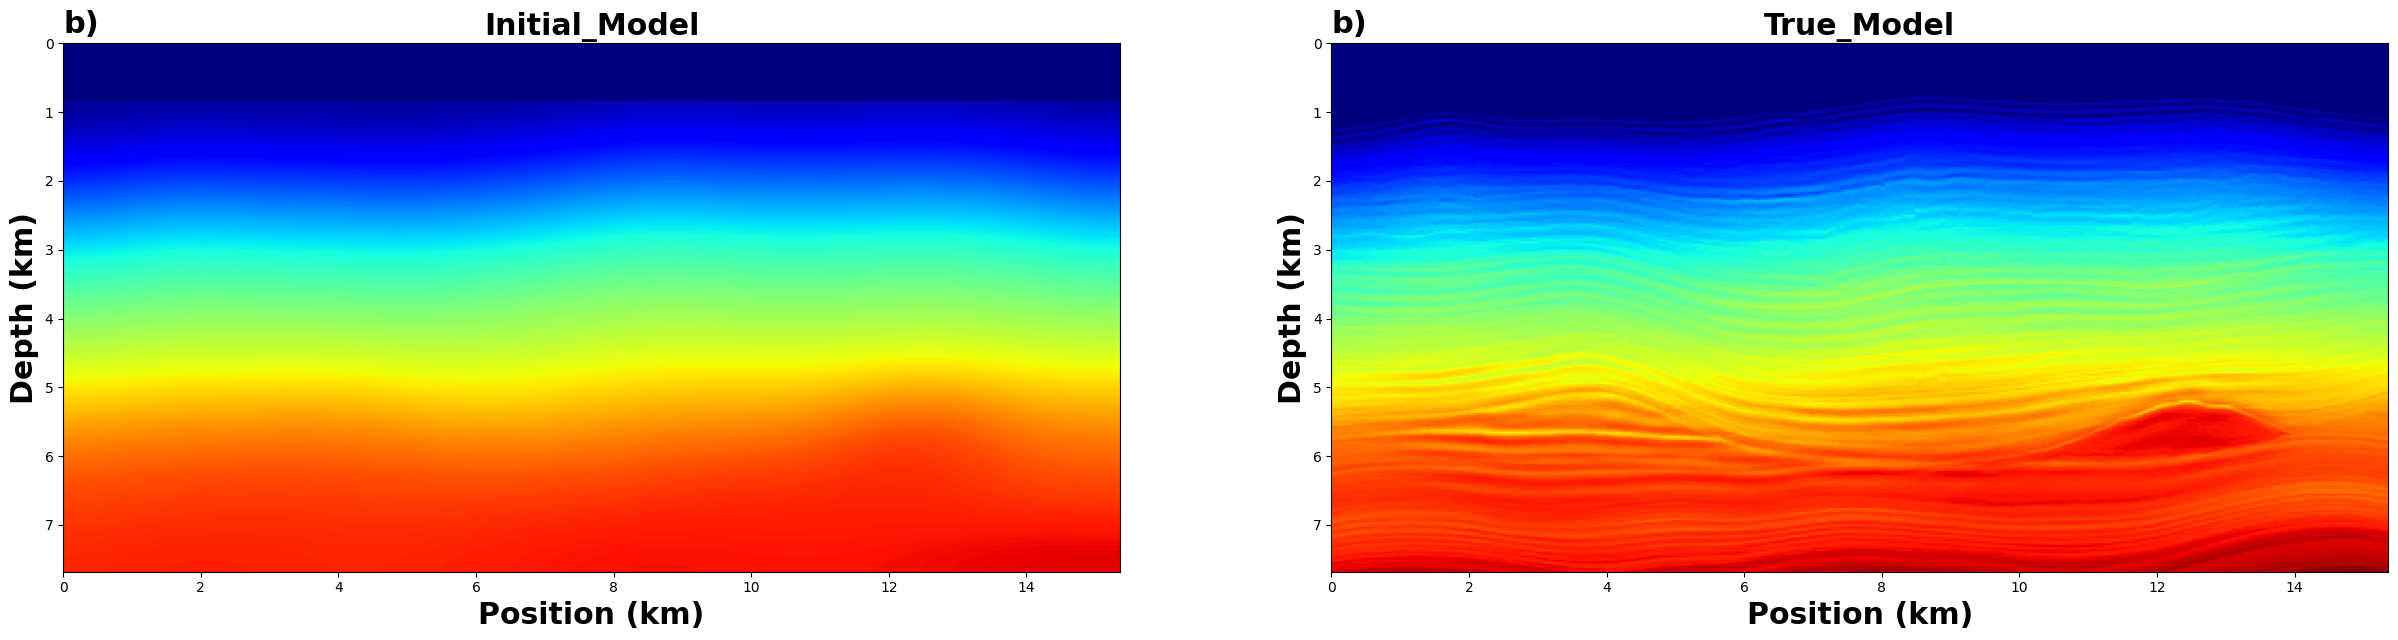

In [4]:
from matplotlib.ticker import MaxNLocator
import matplotlib.pyplot as plt
font = {
        'weight' : 'bold',
        'size'   : 18}

y = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8])
box_min = 1500
box_max = 4800

f, ax = plt.subplots(1,2,figsize=(30, 13))
plt.rc('font', **font)


im = ax[0].imshow(model.detach().cpu(), cmap='jet', vmin=box_min, vmax=box_max, 
                extent=[0, model_init.shape[1] * dx / 1000, model_init.shape[0] * dx / 1000, 0])
ax[0].set_xlabel('Position (km)',fontsize='large', fontweight='bold')
ax[0].set_ylabel('Depth (km)',fontsize='large', fontweight='bold')
ax[0].set_title('Initial_Model',fontsize='large', fontweight='bold')
ax[0].text(0, -0.15, 'b)', fontsize = 22) 
ax[0].xaxis.set_major_locator(MaxNLocator(integer=True))
ax[0].set_yticks(np.arange(y.min(), y.max(), 1)) 

model1 = model_true.detach().cpu().numpy()
im = ax[1].imshow(model1, cmap='jet', vmin=box_min, vmax=box_max, 
                extent=[0, model1.shape[1] * dx / 1000, model1.shape[0] * dx / 1000, 0])
ax[1].set_xlabel('Position (km)',fontsize='large', fontweight='bold')
ax[1].set_ylabel('Depth (km)',fontsize='large', fontweight='bold')
ax[1].set_title('True_Model',fontsize='large', fontweight='bold')
ax[1].text(0, -0.15, 'b)', fontsize = 22) 
ax[1].xaxis.set_major_locator(MaxNLocator(integer=True))
ax[1].set_yticks(np.arange(y.min(), y.max(), 1)) 


plt.show()

## Setting Up the Diffusion Modules

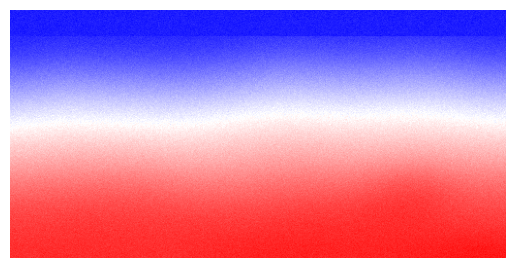

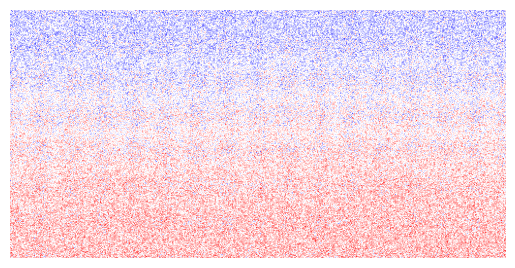

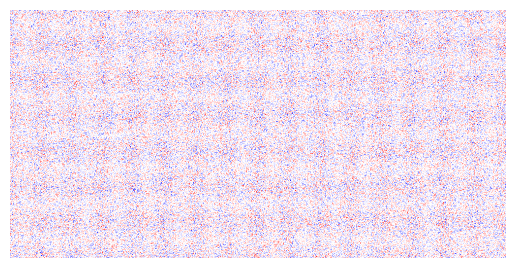

In [5]:
import scipy.io as sio
import torch.nn.functional as F
from utils.Diff_Utils import *
BT = 128
timesteps = 1000
model1 = model.clone()
model1 = model/model.max().abs()

gaussian_diffusion = GaussianDiffusion(timesteps=timesteps)
x_noisyall = []
for idx, t in enumerate([0, 99, timesteps-1]):    
    x_noisy = gaussian_diffusion.q_sample(model1.to(device), t=torch.tensor([t]).to(device))
    plt.figure()
    plt.imshow(x_noisy.detach().cpu(),cmap="bwr")
    plt.axis("off")

In [6]:
from torchsummary import summary
from Model.Module22_Diff_31 import *
import  torch


#Learning Schedule
def lr_lambda(epoch):
    return 10
def lr_lambda1(epoch):
    return 1/2

sim_lr = 1e-4
# define model and diffusion
device = "cuda" if torch.cuda.is_available() else "cpu"
netD = UNetModel(
    in_channels=1,
    model_channels=64,
    out_channels=1,
    num_res_blocks=4,
    attention_resolutions=(8, 16),
    dropout=0,
    channel_mult=(1, 2, 2),
    conv_resample=True,
    num_heads=4
)

### init the hyper-parameters of netD ###
netD = netD.to(device)
timesteps = 1000
batch_size = 8
num_epochs = 1000
ema_decay = 0.999
gaussian_diffusion = GaussianDiffusion(timesteps=timesteps)

"""Compute number of parameters"""
s  = sum(np.prod(list(p.size())) for p in netD.parameters())
print ('Number of netD params: %d' % s)

#summary(netD,[(1,nt,num_receivers_per_shot),(1,nt,num_receivers_per_shot)])


############## Init  ################# 
SNR = 0.0
SSIM = 0.0
Loss = 0.0
ERROR = 0.0

pa = 'Model/netD_ema256_MorePatches'
netD.load_state_dict(torch.load(pa, weights_only=True))



Number of netD params: 9941761


/home/sadalyom/.conda/envs/DAS_Denoising_Torch/lib/python3.8/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


<All keys matched successfully>

## DIIP-FWI

/home/sadalyom/.conda/envs/DAS_Denoising_Torch/lib/python3.8/site-packages/torch/nn/modules/conv.py:456: UserWarning: Applied workaround for CuDNN issue, install nvrtc.so (Triggered internally at /opt/conda/conda-bld/pytorch_1699449185072/work/aten/src/ATen/native/cudnn/Conv_v8.cpp:80.)
  return F.conv2d(input, weight, bias, self.stride,


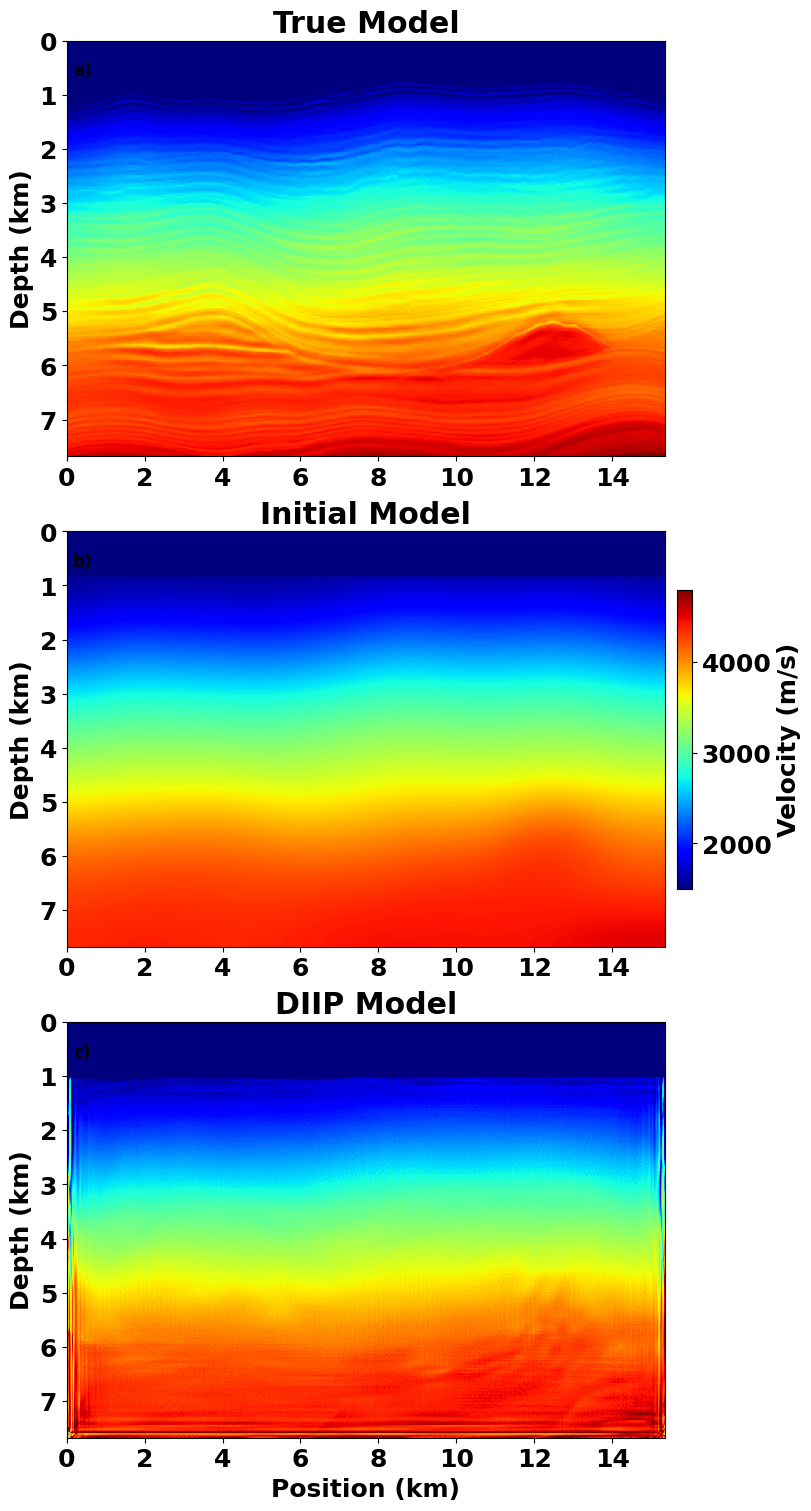

Epoch:    1 | t_int: 100 | K_inv:  3 | K_ddim:  3 | Loss: 1.24e-02 | lr_delta: 1.00e-03 | SNR: 26.733 | SSIM: 0.3273
Epoch:    2 | t_int: 100 | K_inv:  3 | K_ddim:  3 | Loss: 1.17e-02 | lr_delta: 1.00e-03 | SNR: 26.786 | SSIM: 0.3300
Epoch:    3 | t_int: 100 | K_inv:  3 | K_ddim:  3 | Loss: 1.13e-02 | lr_delta: 1.00e-03 | SNR: 26.811 | SSIM: 0.3336
Epoch:    4 | t_int: 100 | K_inv:  3 | K_ddim:  3 | Loss: 1.08e-02 | lr_delta: 1.00e-03 | SNR: 26.813 | SSIM: 0.3359
Epoch:    5 | t_int:  99 | K_inv:  3 | K_ddim:  3 | Loss: 1.05e-02 | lr_delta: 1.00e-03 | SNR: 26.852 | SSIM: 0.3375
Epoch:    6 | t_int:  99 | K_inv:  3 | K_ddim:  3 | Loss: 9.93e-03 | lr_delta: 1.00e-03 | SNR: 26.859 | SSIM: 0.3399
Epoch:    7 | t_int:  99 | K_inv:  3 | K_ddim:  3 | Loss: 9.40e-03 | lr_delta: 1.00e-03 | SNR: 26.862 | SSIM: 0.3434
Epoch:    8 | t_int:  98 | K_inv:  3 | K_ddim:  3 | Loss: 9.21e-03 | lr_delta: 1.00e-03 | SNR: 26.965 | SSIM: 0.3500
Epoch:    9 | t_int:  97 | K_inv:  3 | K_ddim:  3 | Loss: 8.90e-

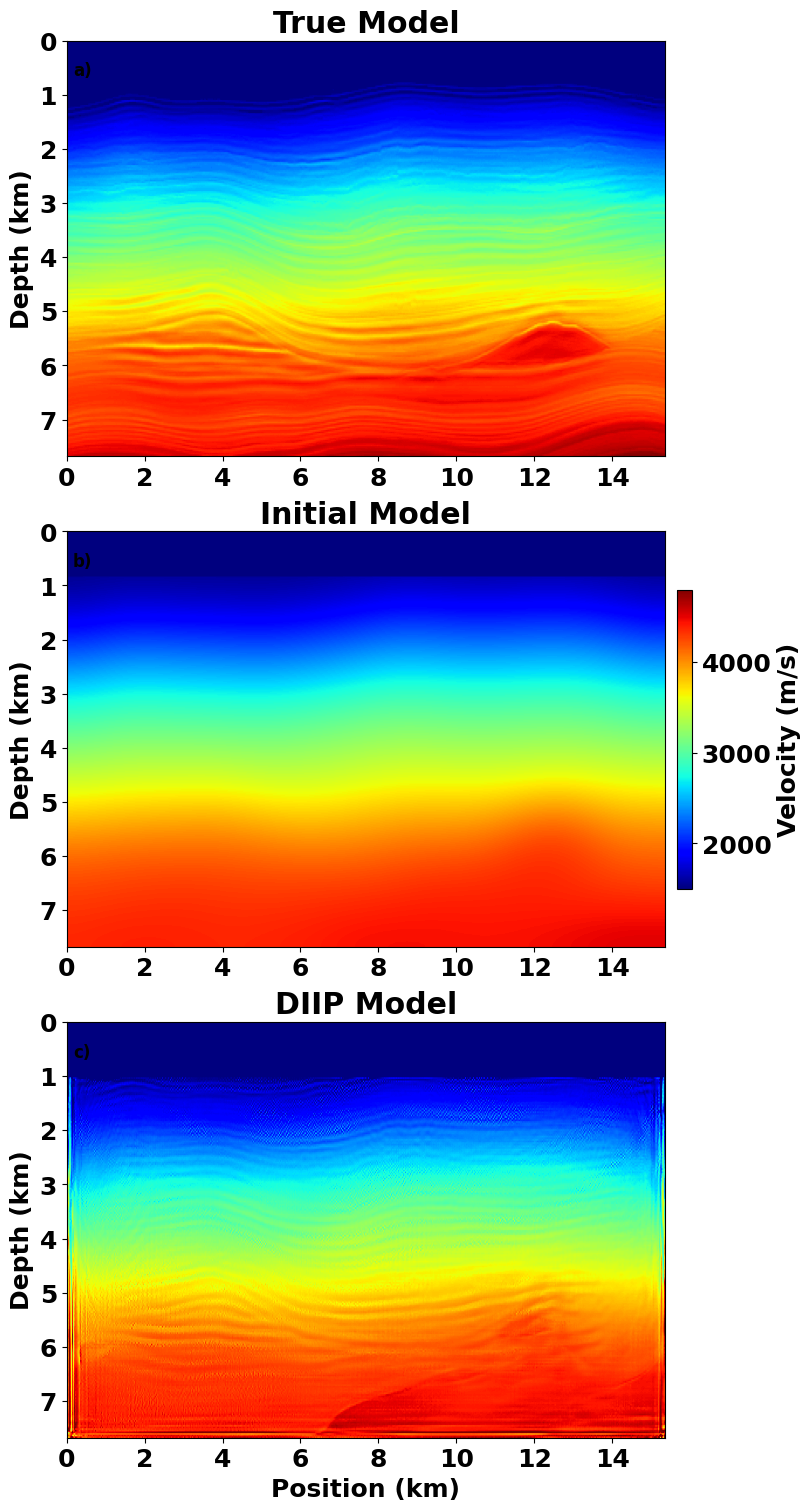

Epoch:   25 | t_int:  76 | K_inv:  3 | K_ddim:  3 | Loss: 5.80e-03 | lr_delta: 1.00e-03 | SNR: 28.212 | SSIM: 0.4520
Epoch:   26 | t_int:  74 | K_inv:  3 | K_ddim:  3 | Loss: 5.74e-03 | lr_delta: 1.00e-03 | SNR: 28.335 | SSIM: 0.4589
Epoch:   27 | t_int:  72 | K_inv:  3 | K_ddim:  3 | Loss: 5.82e-03 | lr_delta: 1.00e-03 | SNR: 28.447 | SSIM: 0.4651
Epoch:   28 | t_int:  70 | K_inv:  3 | K_ddim:  3 | Loss: 5.76e-03 | lr_delta: 1.00e-03 | SNR: 28.562 | SSIM: 0.4699
Epoch:   29 | t_int:  68 | K_inv:  3 | K_ddim:  3 | Loss: 5.62e-03 | lr_delta: 1.00e-03 | SNR: 28.682 | SSIM: 0.4738
Epoch:   30 | t_int:  65 | K_inv:  3 | K_ddim:  3 | Loss: 5.34e-03 | lr_delta: 1.00e-03 | SNR: 28.934 | SSIM: 0.4840
Epoch:   31 | t_int:  63 | K_inv:  3 | K_ddim:  3 | Loss: 5.41e-03 | lr_delta: 1.00e-03 | SNR: 28.934 | SSIM: 0.4815
Epoch:   32 | t_int:  60 | K_inv:  3 | K_ddim:  3 | Loss: 5.49e-03 | lr_delta: 1.00e-03 | SNR: 29.161 | SSIM: 0.4887
Epoch:   33 | t_int:  58 | K_inv:  3 | K_ddim:  3 | Loss: 5.45e-

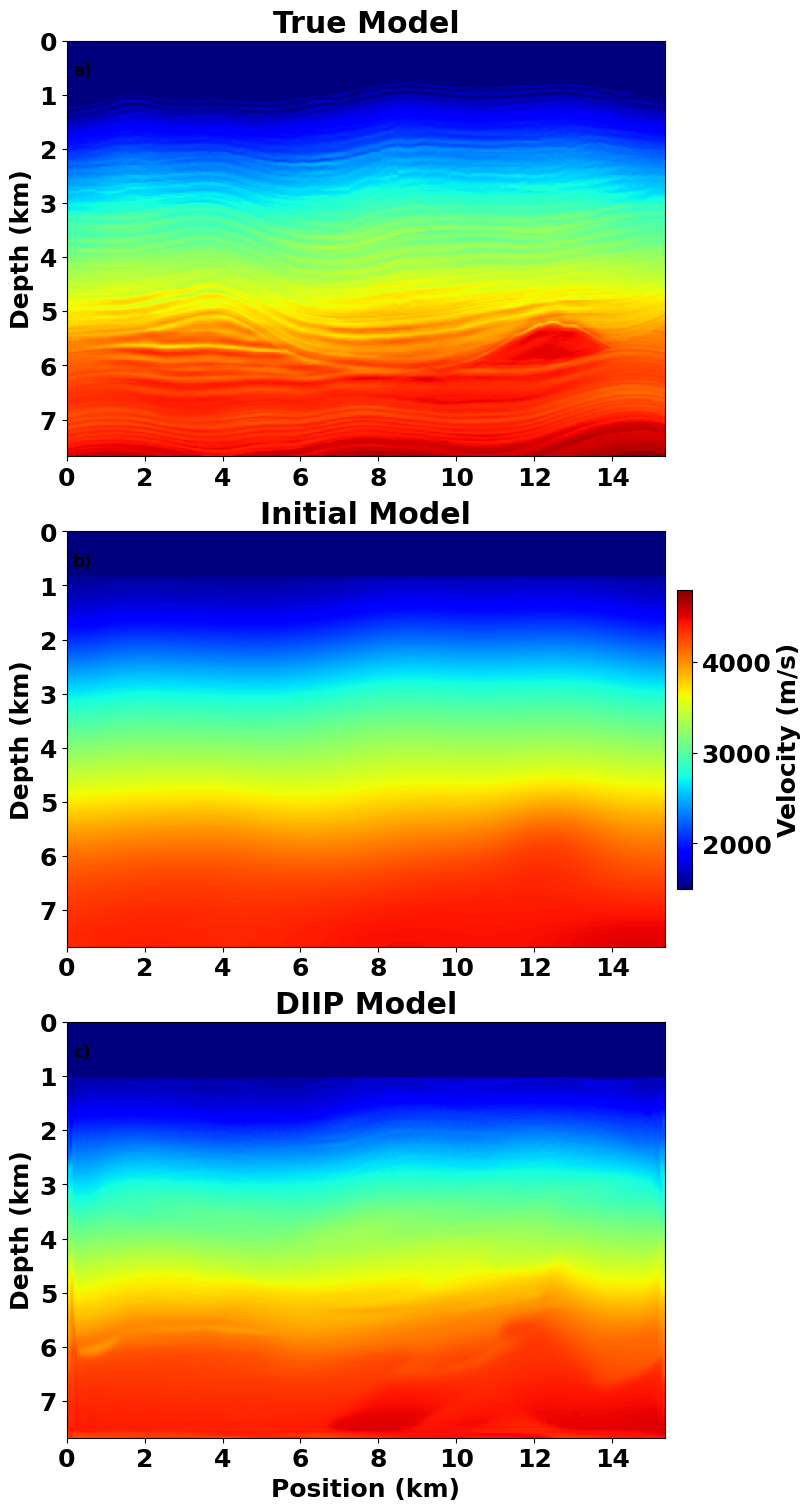

Epoch:   50 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 7.80e-03 | lr_delta: 1.00e-03 | SNR: 32.265 | SSIM: 0.4216
Epoch:   51 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 7.33e-03 | lr_delta: 1.00e-03 | SNR: 32.319 | SSIM: 0.4319
Epoch:   52 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 7.82e-03 | lr_delta: 1.00e-03 | SNR: 32.378 | SSIM: 0.4435
Epoch:   53 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 7.04e-03 | lr_delta: 1.00e-03 | SNR: 32.429 | SSIM: 0.4521
Epoch:   54 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 6.75e-03 | lr_delta: 1.00e-03 | SNR: 32.477 | SSIM: 0.4600
Epoch:   55 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 6.22e-03 | lr_delta: 1.00e-03 | SNR: 32.522 | SSIM: 0.4673
Epoch:   56 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 6.53e-03 | lr_delta: 1.00e-03 | SNR: 32.568 | SSIM: 0.4736
Epoch:   57 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 6.34e-03 | lr_delta: 1.00e-03 | SNR: 32.628 | SSIM: 0.4836
Epoch:   58 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 6.11e-

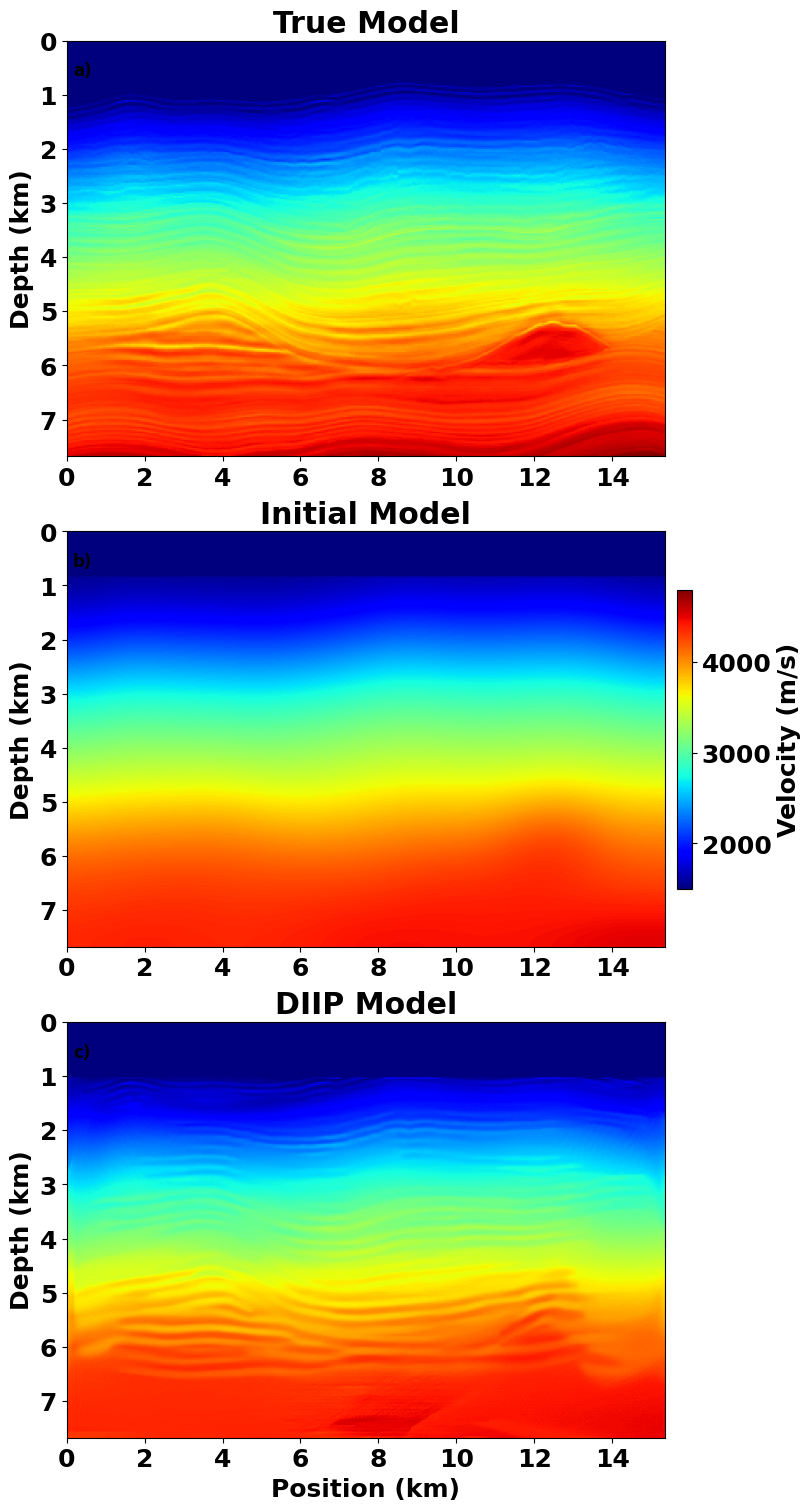

Epoch:   75 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 4.50e-03 | lr_delta: 1.00e-03 | SNR: 33.380 | SSIM: 0.6408
Epoch:   76 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 4.10e-03 | lr_delta: 1.00e-03 | SNR: 33.391 | SSIM: 0.6454
Epoch:   77 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 4.48e-03 | lr_delta: 1.00e-03 | SNR: 33.406 | SSIM: 0.6473
Epoch:   78 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 4.37e-03 | lr_delta: 1.00e-03 | SNR: 33.411 | SSIM: 0.6502
Epoch:   79 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 4.52e-03 | lr_delta: 1.00e-03 | SNR: 33.418 | SSIM: 0.6528
Epoch:   80 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 4.40e-03 | lr_delta: 1.00e-03 | SNR: 33.430 | SSIM: 0.6543
Epoch:   81 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 4.31e-03 | lr_delta: 1.00e-03 | SNR: 33.440 | SSIM: 0.6571
Epoch:   82 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 4.43e-03 | lr_delta: 1.00e-03 | SNR: 33.450 | SSIM: 0.6586
Epoch:   83 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.86e-

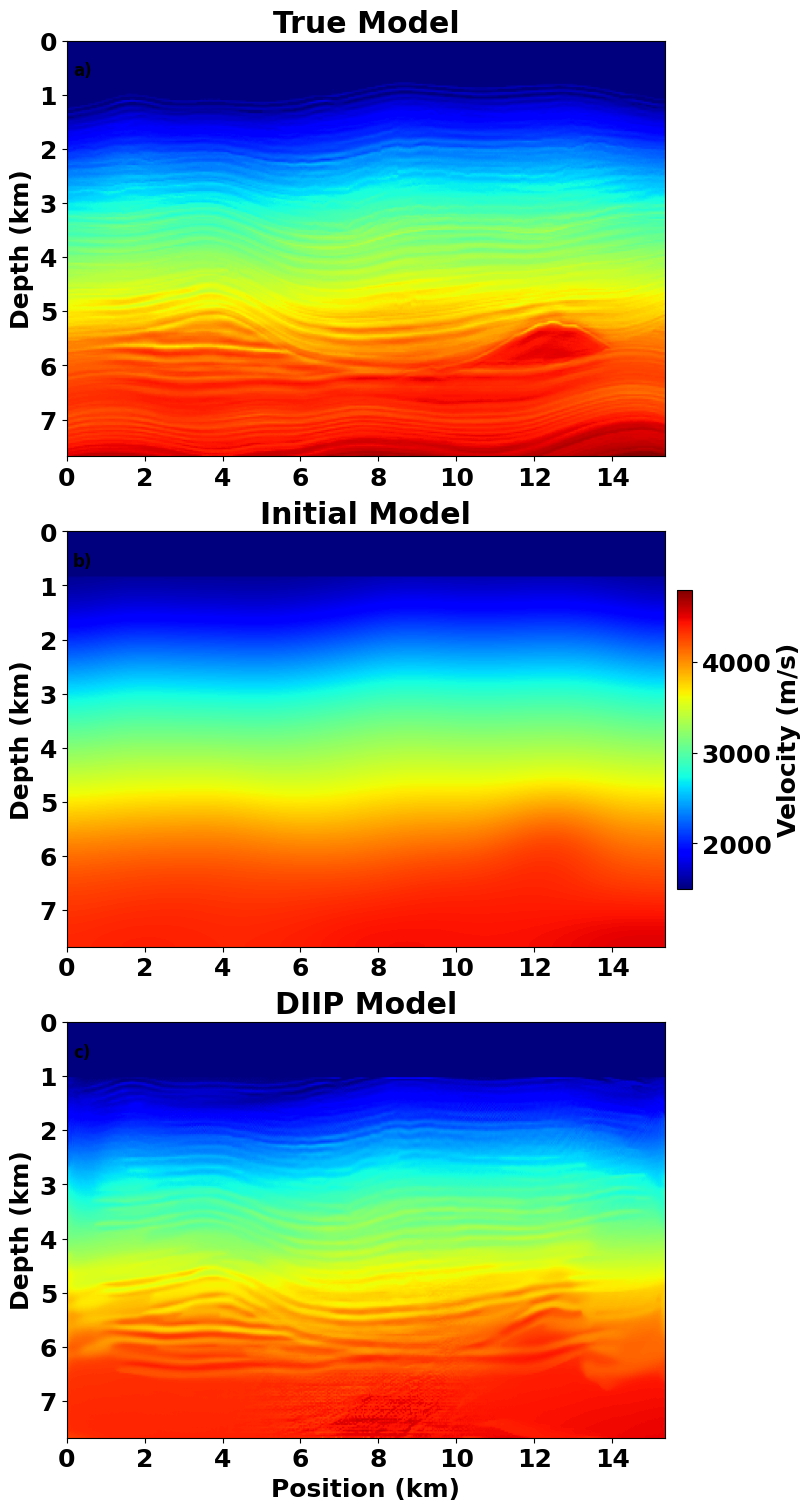

Epoch:  100 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.52e-03 | lr_delta: 1.00e-03 | SNR: 33.586 | SSIM: 0.6808
Epoch:  101 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 4.23e-03 | lr_delta: 1.00e-03 | SNR: 33.587 | SSIM: 0.6811
Epoch:  102 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 4.24e-03 | lr_delta: 1.00e-03 | SNR: 33.600 | SSIM: 0.6820
Epoch:  103 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.99e-03 | lr_delta: 1.00e-03 | SNR: 33.609 | SSIM: 0.6833
Epoch:  104 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.85e-03 | lr_delta: 1.00e-03 | SNR: 33.618 | SSIM: 0.6845
Epoch:  105 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.49e-03 | lr_delta: 1.00e-03 | SNR: 33.619 | SSIM: 0.6848
Epoch:  106 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.86e-03 | lr_delta: 1.00e-03 | SNR: 33.624 | SSIM: 0.6849
Epoch:  107 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.44e-03 | lr_delta: 1.00e-03 | SNR: 33.632 | SSIM: 0.6852
Epoch:  108 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.42e-

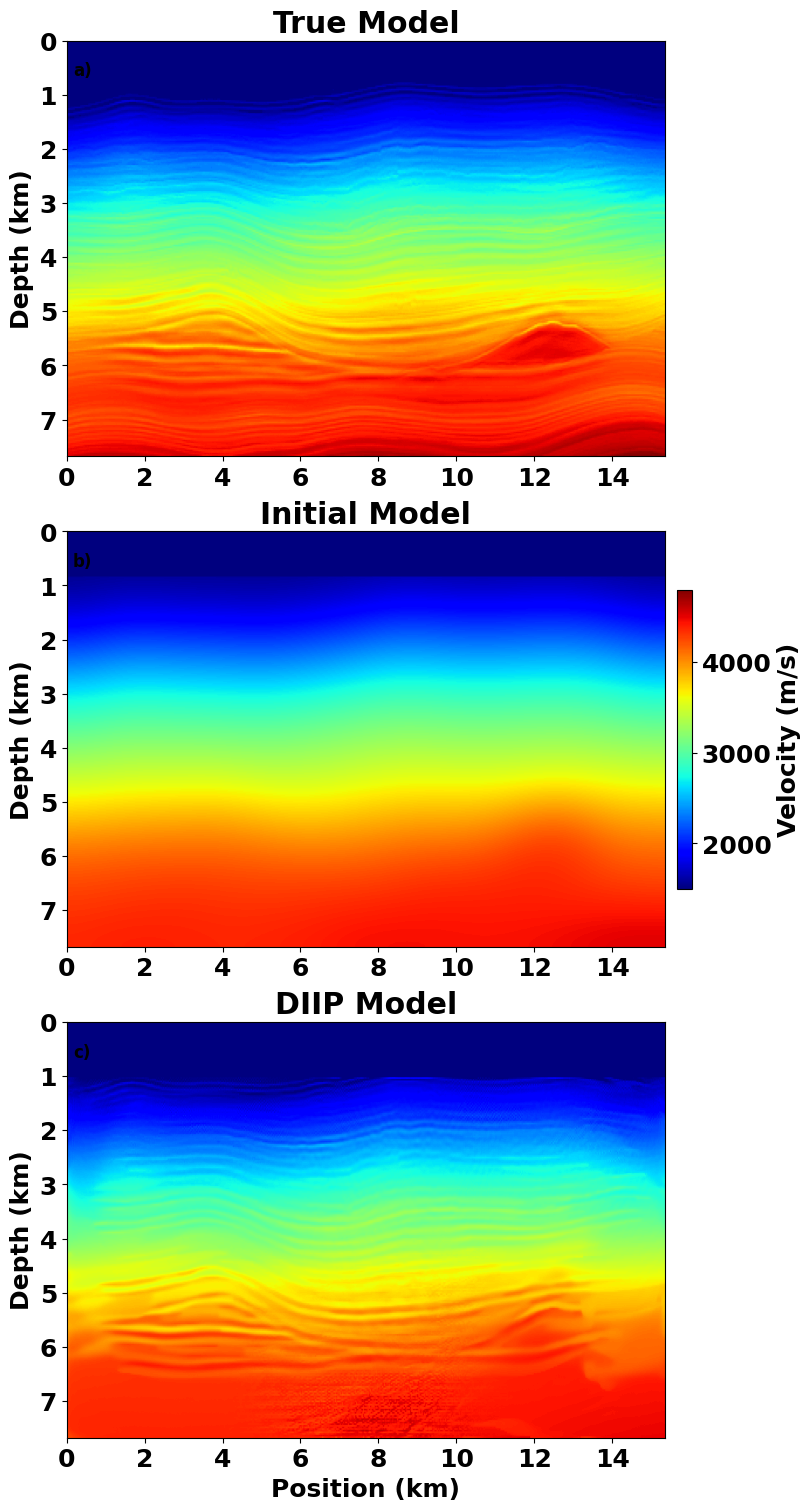

Epoch:  125 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.32e-03 | lr_delta: 1.00e-03 | SNR: 33.769 | SSIM: 0.6986
Epoch:  126 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.94e-03 | lr_delta: 1.00e-03 | SNR: 33.775 | SSIM: 0.6992
Epoch:  127 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.38e-03 | lr_delta: 1.00e-03 | SNR: 33.785 | SSIM: 0.6997
Epoch:  128 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.26e-03 | lr_delta: 1.00e-03 | SNR: 33.794 | SSIM: 0.7008
Epoch:  129 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.30e-03 | lr_delta: 1.00e-03 | SNR: 33.808 | SSIM: 0.7014
Epoch:  130 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.58e-03 | lr_delta: 1.00e-03 | SNR: 33.816 | SSIM: 0.7024
Epoch:  131 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.99e-03 | lr_delta: 1.00e-03 | SNR: 33.825 | SSIM: 0.7035
Epoch:  132 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.57e-03 | lr_delta: 1.00e-03 | SNR: 33.831 | SSIM: 0.7037
Epoch:  133 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.14e-

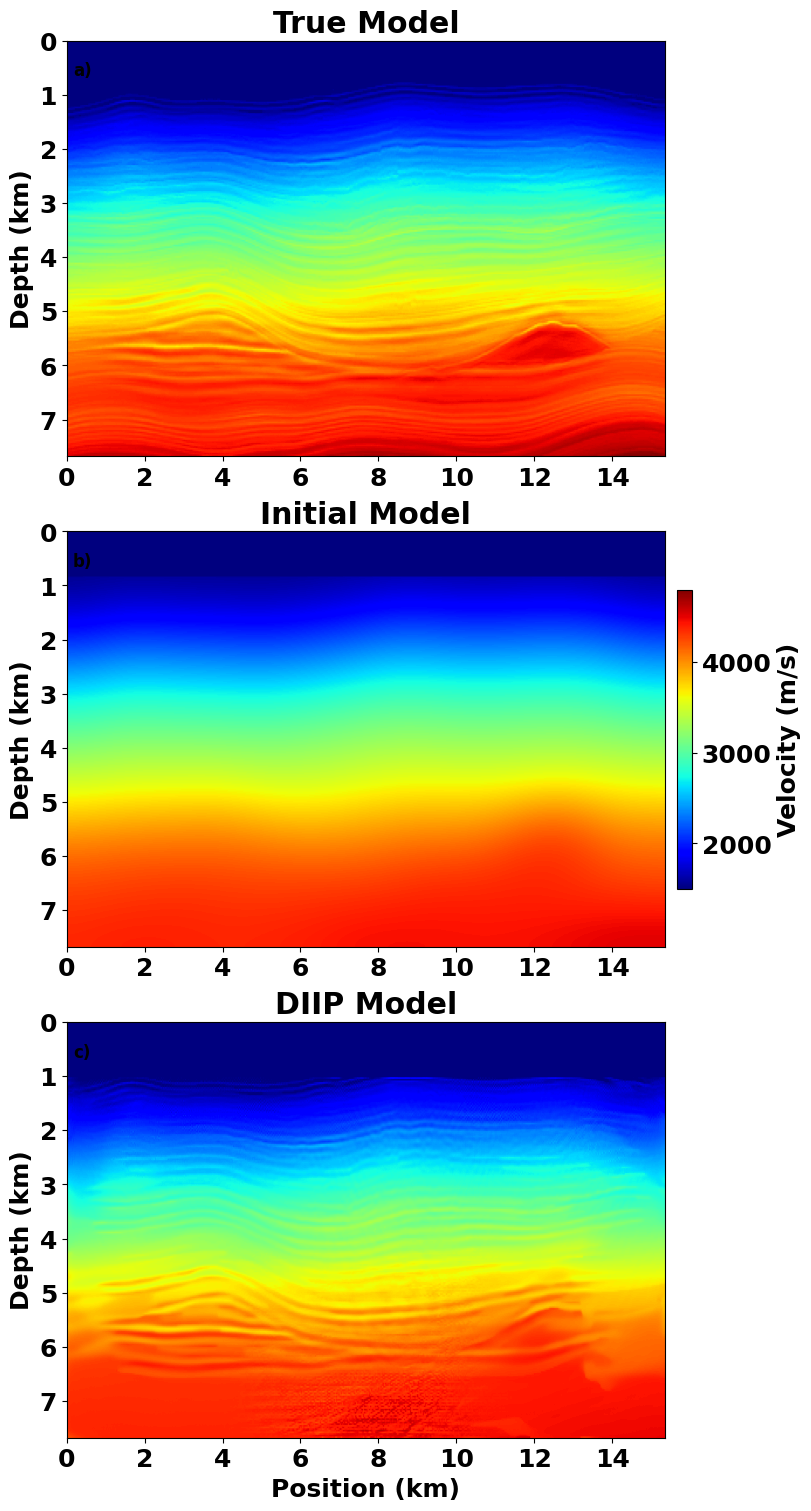

Epoch:  150 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.26e-03 | lr_delta: 1.00e-03 | SNR: 33.928 | SSIM: 0.7134
Epoch:  151 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.01e-03 | lr_delta: 1.00e-03 | SNR: 33.930 | SSIM: 0.7146
Epoch:  152 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.79e-03 | lr_delta: 1.00e-03 | SNR: 33.933 | SSIM: 0.7146
Epoch:  153 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.27e-03 | lr_delta: 1.00e-03 | SNR: 33.932 | SSIM: 0.7145
Epoch:  154 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.97e-03 | lr_delta: 1.00e-03 | SNR: 33.933 | SSIM: 0.7144
Epoch:  155 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.91e-03 | lr_delta: 1.00e-03 | SNR: 33.938 | SSIM: 0.7148
Epoch:  156 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.25e-03 | lr_delta: 1.00e-03 | SNR: 33.944 | SSIM: 0.7153
Epoch:  157 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.20e-03 | lr_delta: 1.00e-03 | SNR: 33.951 | SSIM: 0.7155
Epoch:  158 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.45e-

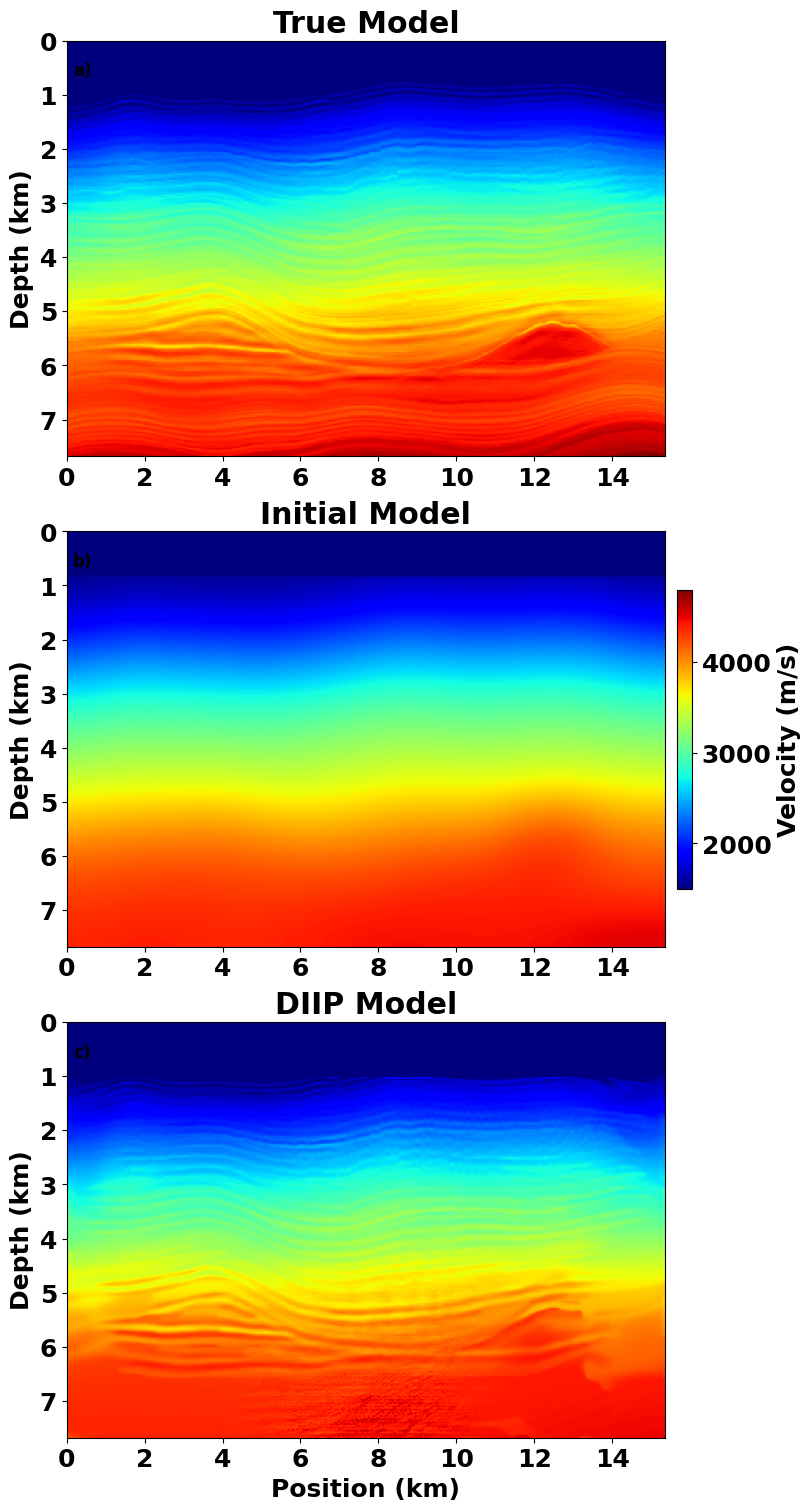

Epoch:  175 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.12e-03 | lr_delta: 1.00e-03 | SNR: 33.993 | SSIM: 0.7195
Epoch:  176 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.87e-03 | lr_delta: 1.00e-03 | SNR: 33.990 | SSIM: 0.7192
Epoch:  177 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.09e-03 | lr_delta: 1.00e-03 | SNR: 33.998 | SSIM: 0.7198
Epoch:  178 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.54e-03 | lr_delta: 1.00e-03 | SNR: 34.002 | SSIM: 0.7204
Epoch:  179 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.00e-03 | lr_delta: 1.00e-03 | SNR: 34.004 | SSIM: 0.7205
Epoch:  180 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.29e-03 | lr_delta: 1.00e-03 | SNR: 34.010 | SSIM: 0.7210
Epoch:  181 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.28e-03 | lr_delta: 1.00e-03 | SNR: 34.012 | SSIM: 0.7209
Epoch:  182 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.19e-03 | lr_delta: 1.00e-03 | SNR: 34.015 | SSIM: 0.7214
Epoch:  183 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 3.25e-

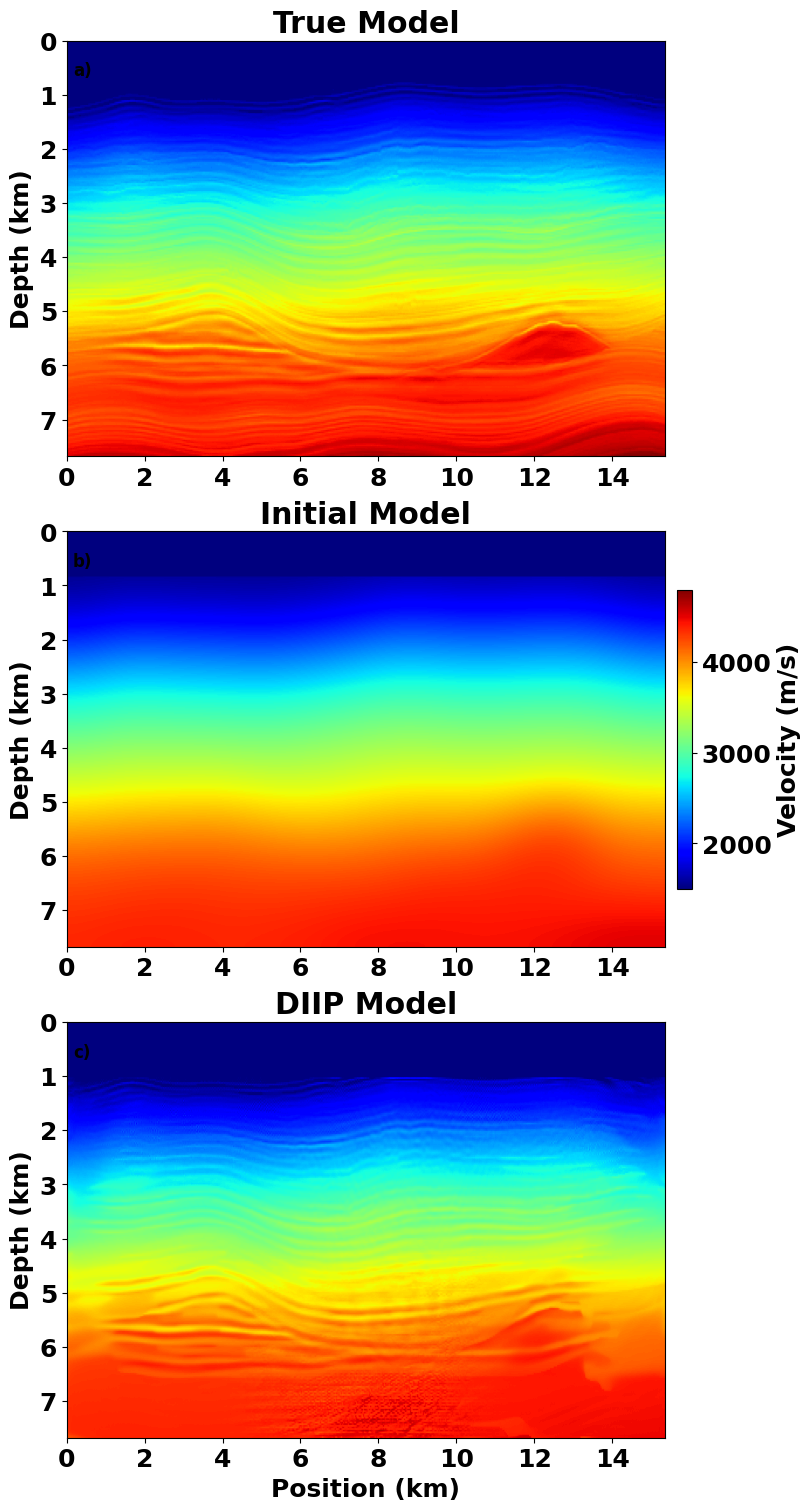

Epoch:  200 | t_int:   1 | K_inv:  3 | K_ddim:  3 | Loss: 2.79e-03 | lr_delta: 1.00e-03 | SNR: 34.046 | SSIM: 0.7230
Done in 6.62 min


In [7]:
 
import time
import numpy as np
import torch
import torch.nn.functional as F


# ============================================================
# SETTINGS (tune)
# ============================================================
# DIIP / DDIM

vmin = 1500.0
vmax = 4800.0
w1, w2 = 256, 256
o1, o2 = w1 // 2, w2 // 2
nz = model_true.shape[0]
ny = model_true.shape[1]

t_start, t_end   = 100, 1              # schedule high->low
warm_epochs      = 50
power_t          = 2.0

K                = 3                    # reverse DDIM steps (expensive, in-graph)
Kf               = 3
eta_ddim         = 0                  # deterministic (DIIP / inversion)

patch_chunk      = 1                    # chunk patches to fit VRAM (1,2,4...)
use_checkpoint   = True                 # if your chunked function supports it
use_amp          = True
amp_dtype        = torch.float16

# delta optimization
lr_start, lr_end = 1e-3, 1e-3
power_lr         = 2.0
grad_clip        = 1

# forward modeling batching
shot_batch       = 4                    # try 4/8/16 (depends on DeepWave memory)

# optional restart of delta

# ============================================================
# Freeze diffusion netD
# ============================================================
netD.eval()
for p in netD.parameters():
    p.requires_grad_(False)

scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

# ============================================================


# ============================================================
# Prepare base model (velocity)
# ============================================================
v_base = model.clone().detach().to(device)     # (H,W)
H, W = v_base.shape
model_true2d = model_true.view(nz, ny)

# ============================================================
# Build initial patches from base
# ============================================================
def vel_to_patches(v):
    v_n = normalize_vel(v,vmin,vmax)  # [-1,1]
    return patch_torch(v_n, w1, w2, o1, o2).reshape(-1, 1, w1, w2)

def patches_to_vel(x0_hat, H, W):
    v_new_n = patch_inv_torch_gaussian(
        x0_hat.reshape(-1, w1 * w2),
        H, W, w1, w2, o1, o2,
        sigma1=w1/6, sigma2=w2/6
    )
    return denormalize_vel(v_new_n,vmin,vmax)

# ============================================================
# Init inversion latent + delta
# ============================================================
v0_p = vel_to_patches(v_base)             # (B,1,w1,w2)
B = v0_p.shape[0]

# initial schedule values
t_int0 = t_start

# invert once (no-grad)
x_t_inv, ts = gaussian_diffusion.ddim_invert_x0_to_xt(
    model=netD,
    x0=v0_p,
    t_start=t_int0,
    K=Kf,
    clip_denoised=False,
    use_amp=False
)
# delta (trainable)
delta = torch.zeros_like(x_t_inv, device=device, requires_grad=True)

optim_delta = torch.optim.Adam([delta], lr=lr_start, betas=(0.5, 0.9), eps=1e-12)

# ============================================================
# Main FWI loop
# ============================================================
t0_global = time.time()

for epoch in range(fwi_num_epochs):

    # ---------------------------
    # schedule t_int and lr
    # ---------------------------
    if epoch < warm_epochs:
        p = epoch / max(1, warm_epochs - 1)
        t_int = int(round(t_start + (t_end - t_start) * (p ** power_t)))
        lr_now = float(lr_start + (lr_end - lr_start) * (p ** power_lr))
    else:
        t_int, lr_now = t_end, float(lr_end)

    for pg in optim_delta.param_groups:
        pg["lr"] = lr_now

    # ---------------------------
    # shots subset
    # ---------------------------
    indx = np.random.permutation(fwi_batch)
    ind = indx[: fwi_batch // 2]
    nshots = len(ind)

    epoch_loss = 0.0
    
    #if epoch<=warm_epochs:
        
    # invert once (no-grad)
    #x_t_inv = ddim_invert_x0_to_xt(gaussian_diffusion, netD, v0_p, t_start=t_int, K=K_inv)
    x_t_inv, ts = gaussian_diffusion.ddim_invert_x0_to_xt(
        model=netD,
        x0=v0_p,
        t_start=t_int,
        K=Kf,
        clip_denoised=False,
        use_amp=False
    )
    # ---------------------------
    # shot mini-batches
    # ---------------------------
    for s0 in range(0, nshots, shot_batch):
        s1 = min(s0 + shot_batch, nshots)
        shot_ids = ind[s0:s1]

        optim_delta.zero_grad(set_to_none=True)

        # ===========================
        # (A) DIIP mapping: latent -> x0_hat -> velocity
        # ===========================
        if use_amp:
            ctx = torch.cuda.amp.autocast(dtype=amp_dtype)
        else:
            from contextlib import nullcontext
            ctx = nullcontext()

        with ctx:
            # take the inverted latent at the CURRENT t_int
            # (simple approach: re-noise x0 to current t_int using the deterministic latent x_t_inv)
            # We keep x_t_inv computed at t_start, but we can still run reverse from t_int
            # by just setting the starting x_t = x_t_inv + delta and calling reverse with t_start=t_int.
            #
            # If you want strict consistency: you can recompute x_t_inv each epoch for the current t_int (costly).
            #
            x_t = x_t_inv + delta

            # reverse DDIM (chunked, differentiable) -> x0_hat
            x0_hat = gaussian_diffusion.ddim_x0_from_xt_with_ts_chunked(
                model=netD,
                x_t=x_t,
                ts=ts,
                eta=0.0,
                clip_denoised=False,
                patch_chunk=patch_chunk,
                use_checkpoint=False,   # for test
                use_amp=False
            )

            # unpatch to velocity
            v_new = patches_to_vel(x0_hat, H, W)

            # smooth below water only (optional)
            #v_s = smooth_velocity_gaussian(v_new, kernel_size=5, sigma=1.0)

            # keep water untouched
            v_new = v_new.clone()
            v_new[:34, :] = 1500.0


            # ===========================
            # (B) Forward modeling loss (SHOT MINI-BATCH)
            # ===========================
            batch_src_amps = source[shot_ids].to(device)
            batch_rcv_true = rcv_amps_true[shot_ids].to(device)
            batch_x_s = x_s[shot_ids].to(device)
            batch_x_r = x_r[shot_ids].to(device)

            batch_rcv_pred = scalar(
                v_new, dx, dt,
                source_amplitudes=batch_src_amps,
                source_locations=batch_x_s,
                receiver_locations=batch_x_r,
                accuracy=8,
                pml_width=pml_width
            )[-1]

            d_real = batch_rcv_true / (torch.norm(batch_rcv_true, p=2) + 1e-12)
            d_fake = batch_rcv_pred / (torch.norm(batch_rcv_pred, p=2) + 1e-12)

            loss = F.pairwise_distance(d_fake, d_real, keepdim=True).mean()

        epoch_loss += float(loss.item()) * (s1 - s0)

        # ===========================
        # (C) Backprop + update delta
        # ===========================
        if use_amp:
            scaler.scale(loss).backward()
            scaler.unscale_(optim_delta)
            torch.nn.utils.clip_grad_norm_([delta], grad_clip)
            scaler.step(optim_delta)
            scaler.update()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_([delta], grad_clip)
            optim_delta.step()

    # normalize epoch loss
    epoch_loss /= max(1, nshots)

    # metrics
    snr = ComputeSNR(v_new.detach().cpu().numpy(), model_true2d.detach().cpu().numpy())
    ssim = ComputeSSIM(v_new.detach().cpu().numpy(), model_true2d.detach().cpu().numpy())

    if (epoch + 1) % 25 == 0 or epoch == 0:
        fig, axes = plot_velocity_models(
            model_true=model_true2d,
            model_init=model_init,
            model_result=v_new,
            dx=dx,
            vmin=vmin,
            vmax=vmax,
            figsize = (8,15),
        )

    print(
        f"Epoch: {epoch+1:4d} | t_int: {t_int:3d} | K_inv: {K:2d} | K_ddim: {K:2d} | "
        f"Loss: {epoch_loss:.2e} | lr_delta: {lr_now:.2e} | "
        f"SNR: {snr:.3f} | SSIM: {float(ssim):.4f}"
    )

t1_global = time.time()
print(f"Done in {(t1_global - t0_global)/60:.2f} min")
spio.savemat(fwi_result + "DIIP_Recon.mat", {"rec": v_new.detach().cpu().numpy()})

## Plotting the Reconstructed Velocity Model

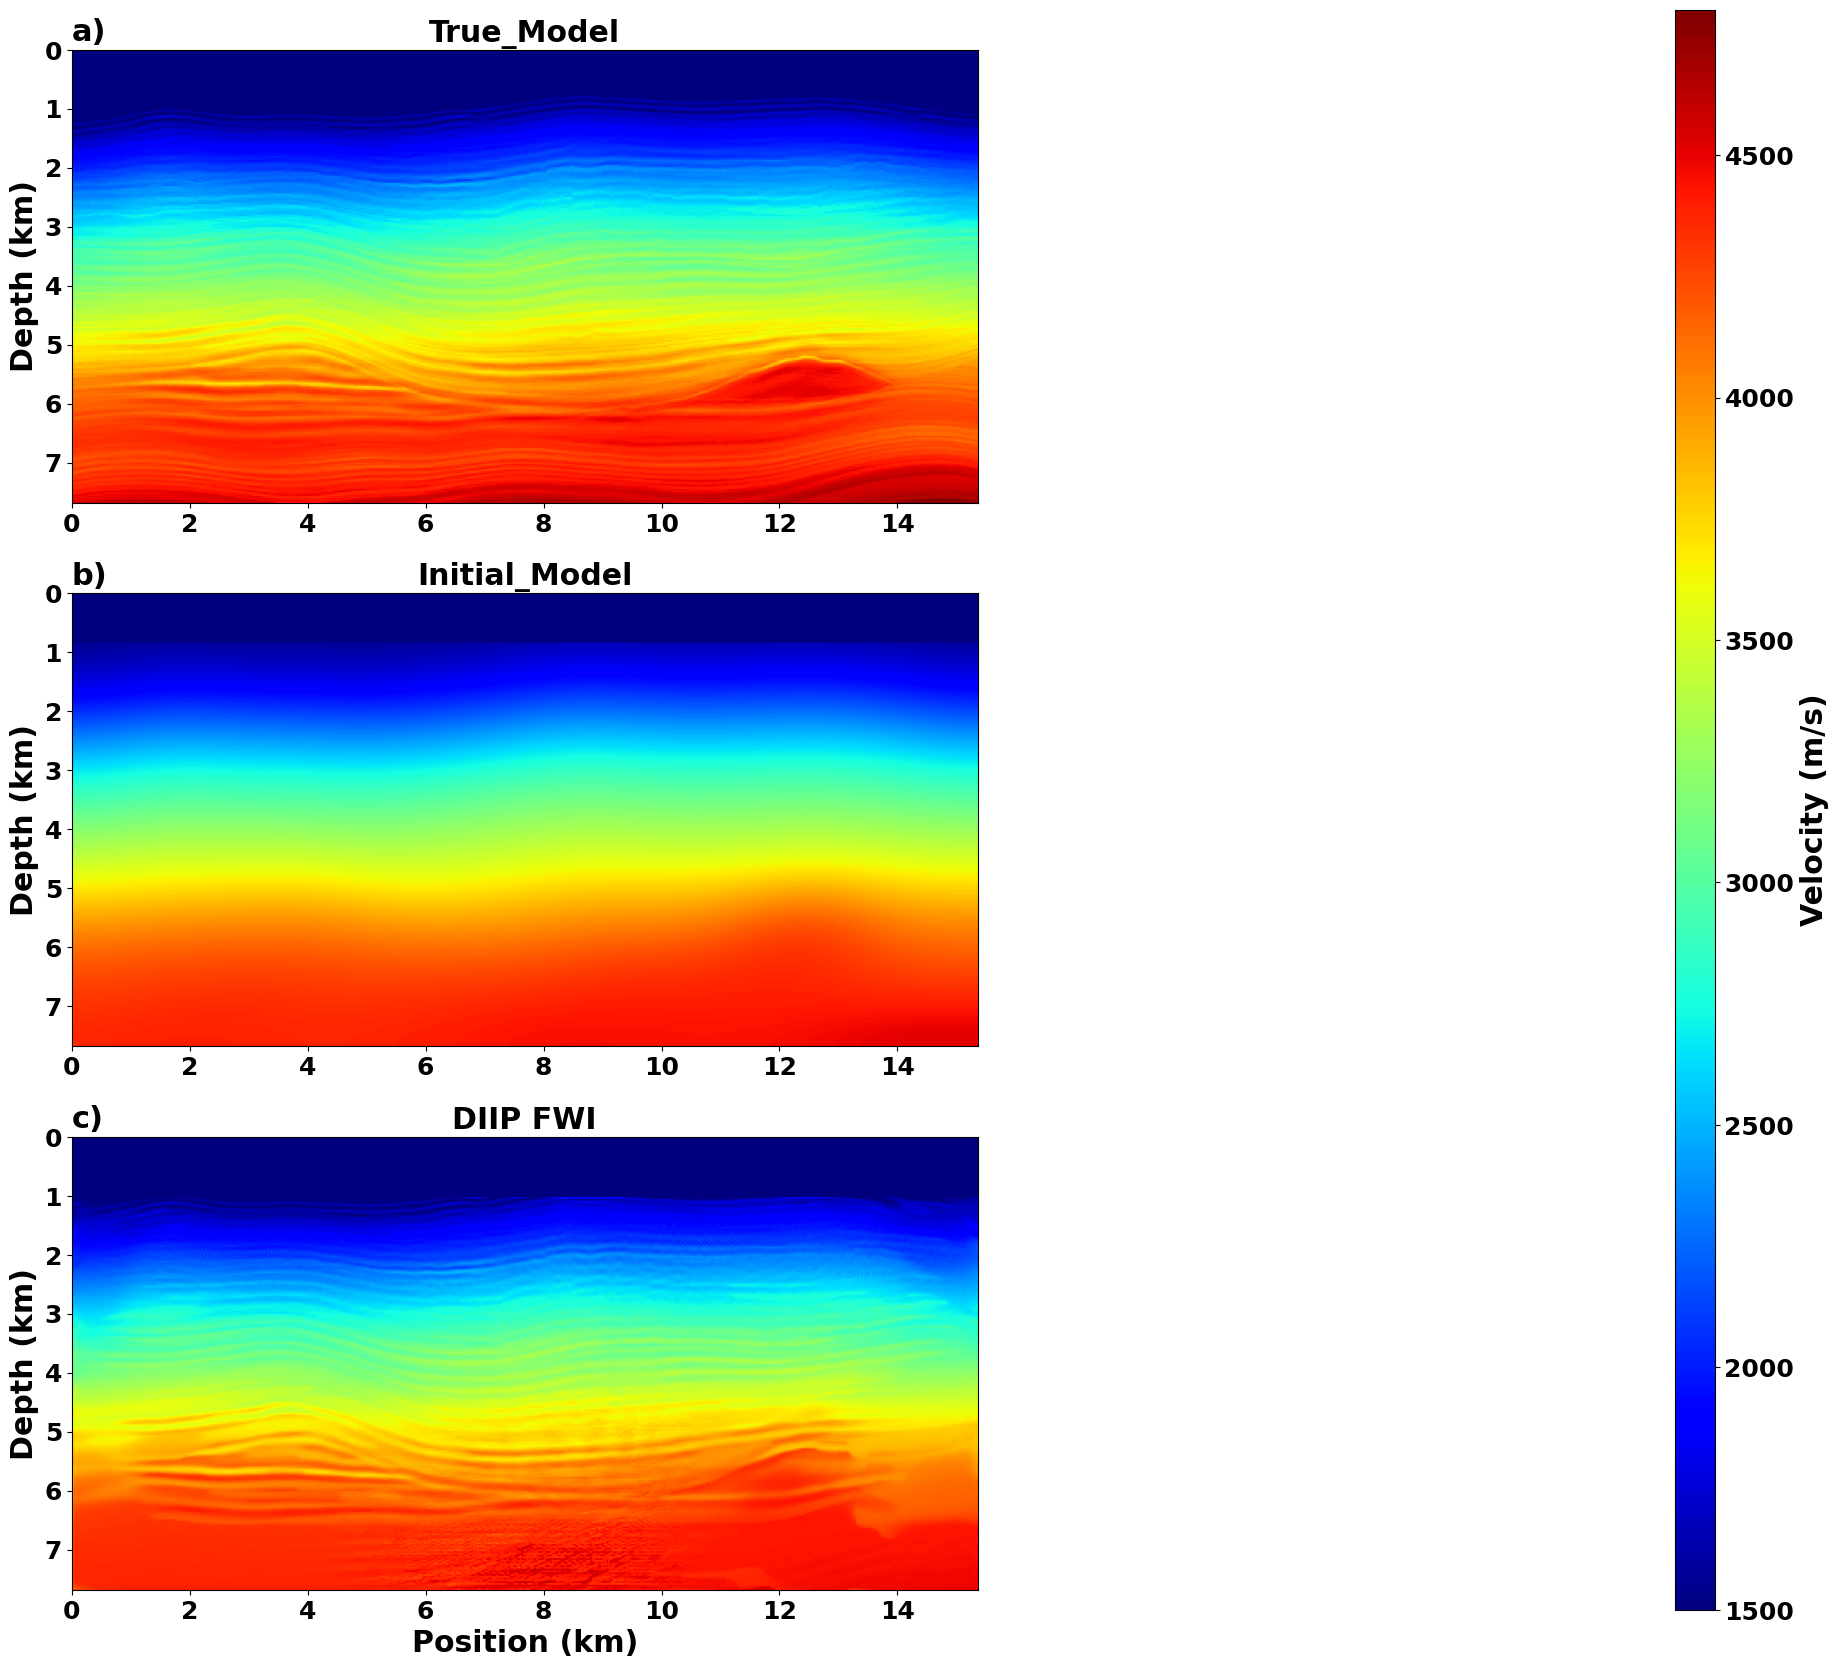

The reconstructed velocity model has SNR: 34.04567655968418 dB and SSIM: 0.7229721


In [9]:
f, ax = plt.subplots(3,1,figsize=(40, 20))
plt.rc('font', **font)

# True Model
modeltrue = model1
im = ax[0].imshow(model_true.detach().cpu().numpy(), cmap='jet', vmin=box_min, vmax=box_max, 
                extent=[0, modeltrue.shape[1] * dx / 1000, modeltrue.shape[0] * dx / 1000, 0])

#ax[0].set_xlabel('Position (km)',fontsize='large', fontweight='bold')
ax[0].set_ylabel('Depth (km)',fontsize='large', fontweight='bold')
ax[0].set_title('True_Model',fontsize='large', fontweight='bold')
ax[0].text(0, -0.15, 'a)', fontsize = 22) 
ax[0].xaxis.set_major_locator(MaxNLocator(integer=True))
ax[0].set_yticks(np.arange(y.min(), y.max(), 1)) 

# Initial Model
init_V = model_init.detach().cpu().numpy()
im = ax[1].imshow(init_V, cmap='jet', vmin=box_min, vmax=box_max, 
                extent=[0, init_V.shape[1] * dx / 1000, init_V.shape[0] * dx / 1000, 0])
#ax[1].set_xlabel('Position (km)',fontsize='large', fontweight='bold')
ax[1].set_ylabel('Depth (km)',fontsize='large', fontweight='bold')
ax[1].set_title('Initial_Model',fontsize='large', fontweight='bold')
ax[1].text(0, -0.15, 'b)', fontsize = 22) 
ax[1].xaxis.set_major_locator(MaxNLocator(integer=True))
ax[1].set_yticks(np.arange(y.min(), y.max(), 1)) 

# Siamese Model
Siamese_Vel = scipy.io.loadmat(fwi_result + 'DIIP_Recon.mat')
Siamese_Vel = Siamese_Vel['rec']
im = ax[2].imshow(Siamese_Vel, cmap='jet', vmin=box_min, vmax=box_max, 
                extent=[0, v_new.shape[1] * dx / 1000, v_new.shape[0] * dx / 1000, 0])
ax[2].set_xlabel('Position (km)',fontsize='large', fontweight='bold')
ax[2].set_ylabel('Depth (km)',fontsize='large', fontweight='bold')
ax[2].set_title('DIIP FWI',fontsize='large', fontweight='bold')
ax[2].text(0, -0.15, 'c)', fontsize = 22) 
ax[2].xaxis.set_major_locator(MaxNLocator(integer=True))
ax[2].set_yticks(np.arange(y.min(), y.max(), 1)) 


cbar_ax = f.add_axes([0.8, 0.1, 0.01, 0.8])
f.colorbar(im, fraction=0.005, pad=0.04,cax=cbar_ax)
cbar_ax.set_ylabel('Velocity (m/s)',fontsize='large', fontweight='bold')

plt.show()

snr = ComputeSNR(Siamese_Vel,  
          model_true.detach().cpu().numpy())

ssim = ComputeSSIM(Siamese_Vel, \
          model_true.detach().cpu().numpy())

print('The reconstructed velocity model has SNR:', str(snr), 'dB', 'and SSIM:',str(ssim.cpu().detach().cpu().numpy()))

## Plotting Velocities Profiles

@Position =  2.4 km, RMSE =  0.045184013286261135 km/s
@Position =  7.2 km, RMSE =  0.05226237052427228 km/s
@Position =  14.4 km, RMSE =  0.08367207035608219 km/s


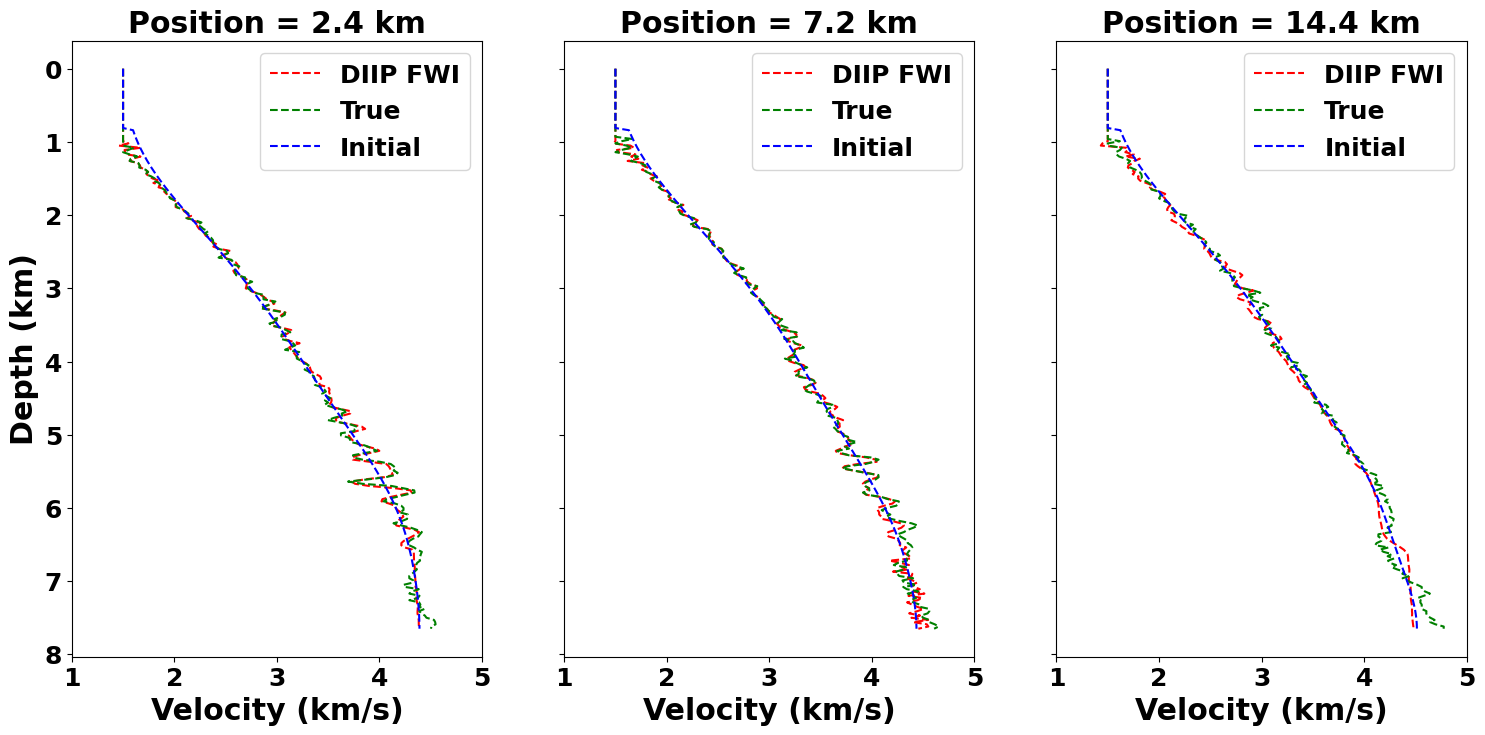

In [10]:
from math import sqrt

# position 1
k = 80

xy = np.arange(0,Siamese_Vel.shape[0] * dx / 1000, len(Siamese_Vel[:,k])/Siamese_Vel.shape[0] * dx / 1000)
f, ax = plt.subplots(figsize=(18, 8), ncols=3,nrows=1)
xx = np.arange(0,5)
ax[0].plot(Siamese_Vel[:,k]/1000,xy,'r--',label='DIIP FWI')
ax[0].plot(model_true.detach().cpu().numpy()[:,k]/1000,xy,'g--',label='True')
ax[0].plot(init_V[:,k]/1000,xy,'b--',label='Initial')
ax[0].set_ylabel('Depth (km)',fontsize='large', fontweight='bold')
ax[0].set_xlabel('Velocity (km/s)',fontsize='large', fontweight='bold')
ax[0].set_xlim([1,5])
ax[0].legend(loc='upper right')
ax[0].set_title( 'Position = ' + str(k * dx / 1000) +' km',fontsize='large', fontweight='bold')
ax[0].invert_yaxis()
rms = sqrt(np.mean(((model_true.detach().cpu().numpy()[:,k]-Siamese_Vel[:,k])/1000)**2))
print('@Position = ', str(k * dx / 1000), 'km, RMSE = ',str(rms), 'km/s')

# position 2
k = 240
xy = np.arange(0,Siamese_Vel.shape[0] * dx / 1000, len(Siamese_Vel[:,k])/Siamese_Vel.shape[0] * dx / 1000)
xx = np.arange(0,4)
ax[1].plot(Siamese_Vel[:,k]/1000,xy,'r--',label='DIIP FWI')
ax[1].plot(model_true.detach().cpu().numpy()[:,k]/1000,xy,'g--',label='True')
ax[1].plot(init_V[:,k]/1000,xy,'b--',label='Initial')
ax[1].set_xlabel('Velocity (km/s)',fontsize='large', fontweight='bold')
ax[1].set_yticklabels([])
ax[1].set_xlim([1,5])
ax[1].legend(loc='upper right')
ax[1].set_title( 'Position = ' + str(k * dx / 1000) +' km',fontsize='large', fontweight='bold')
ax[1].invert_yaxis()
rms = sqrt(np.mean(((model_true.detach().cpu().numpy()[:,k]-Siamese_Vel[:,k])/1000)**2))
print('@Position = ', str(k * dx / 1000), 'km, RMSE = ',str(rms), 'km/s')

# position 3
k = 480
xy = np.arange(0,Siamese_Vel.shape[0] * dx / 1000, len(Siamese_Vel[:,k])/Siamese_Vel.shape[0] * dx / 1000)
xx = np.arange(0,4)
ax[2].plot(Siamese_Vel[:,k]/1000,xy,'r--',label='DIIP FWI')
ax[2].plot(model_true.detach().cpu().numpy()[:,k]/1000,xy,'g--',label='True')
#ax[2].plot(FWIGAN_Vel[:,k]/1000,xy,'y--',label='FWIGAN')
ax[2].plot(init_V[:,k]/1000,xy,'b--',label='Initial')
ax[2].set_xlabel('Velocity (km/s)',fontsize='large', fontweight='bold')
ax[2].set_yticklabels([])
ax[2].set_xlim([1,5])
#ax[2].ylim([0,3.8])
ax[2].legend(loc='upper right')
ax[2].set_title( 'Position = ' + str(k * dx / 1000) +' km',fontsize='large', fontweight='bold')
ax[2].invert_yaxis()
rms = sqrt(np.mean(((model_true.detach().cpu().numpy()[:,k]-Siamese_Vel[:,k])/1000)**2))
print('@Position = ', str(k * dx / 1000), 'km, RMSE = ',str(rms), 'km/s')

